# Monocular / disparity comparison

Two-experiment per-cell comparison: builds the `goggles-monocular` and `goggles-disparity` sessions, computes reliability across both with `CrossExperimentAnalysis`, and plots each reliable cell's stacked response with `CrossExperimentVisualization.make_combined_plot` (no distance/radial band).

In [2]:
import sys, os
import matplotlib.pyplot as plt

base_dir = r"C:\Users\acostamendoza\projects\distance-project"
for p in (base_dir, base_dir + r"\disparity-analysis"):
    if p not in sys.path:
        sys.path.append(p)

from src.data.MonocularDevice import MonocularDevice
from src.data.DisparityDevice import DisparityDevice
from src.comparison.CrossExperimentAnalysis import CrossExperimentAnalysis
from src.comparison.CrossExperimentVisualization import CrossExperimentVisualization
from src.data.split_mixed_session import split_mixed_session

%load_ext autoreload
%autoreload 2

In [3]:
mouse, date, experiment = "SAM047", "260924", "goggles"

base_data_dir = r"D:/data-distance-coding-project/processed-data"
session_dir = os.path.join(base_data_dir, f"{date}_{mouse}_{experiment}")

split_dirs = split_mixed_session(session_dir)

M = MonocularDevice(data_dir=split_dirs["monocular"])
D = DisparityDevice(data_dir=split_dirs["disparity"])

Source: 260924_SAM047_goggles  (mode=mixed, 135 trials)
  binocular=105 monocular=30
  per-trial fields subset: ['eye_order', 'frame_times', 'lead_eye', 'left_eye_end_px', 'left_eye_start_px', 'post_end', 'pre_start', 'right_eye_end_px', 'right_eye_start_px', 'stim_end', 'stim_start', 'trial_cond', 'trial_disparity_deg', 'trial_eye', 'trial_kind', 'trial_start']
  = 260924_SAM047_disparity: stimulus exists, leaving it (overwrite=True to rewrite)
    suite2p: exists
  = 260924_SAM047_monocular: stimulus exists, leaving it (overwrite=True to rewrite)
    suite2p: exists
Directory results already exists
Directory results already exists


In [4]:
# reliability across both experiments (no distance device)
cea = CrossExperimentAnalysis.from_devices(None, M, D)
print("present_eyes:", M.present_eyes)  # both eyes -> threshold keys are 'left'/'right', not 'monocular'

RHO = {'right': 0.75, 'disparity': 0.75}
sets = cea.reliable_each_thresh(RHO, monocular='right')
both = sorted(set(sets['right']) & set(sets['disparity']))
print(f"{len(both)} cells reliable in left eye + disparity at rho >= {RHO}")

present_eyes: ['right', 'left']
2 cells reliable in left eye + disparity at rho >= {'right': 0.75, 'disparity': 0.75}


In [5]:
viz = CrossExperimentVisualization(None, M, D)

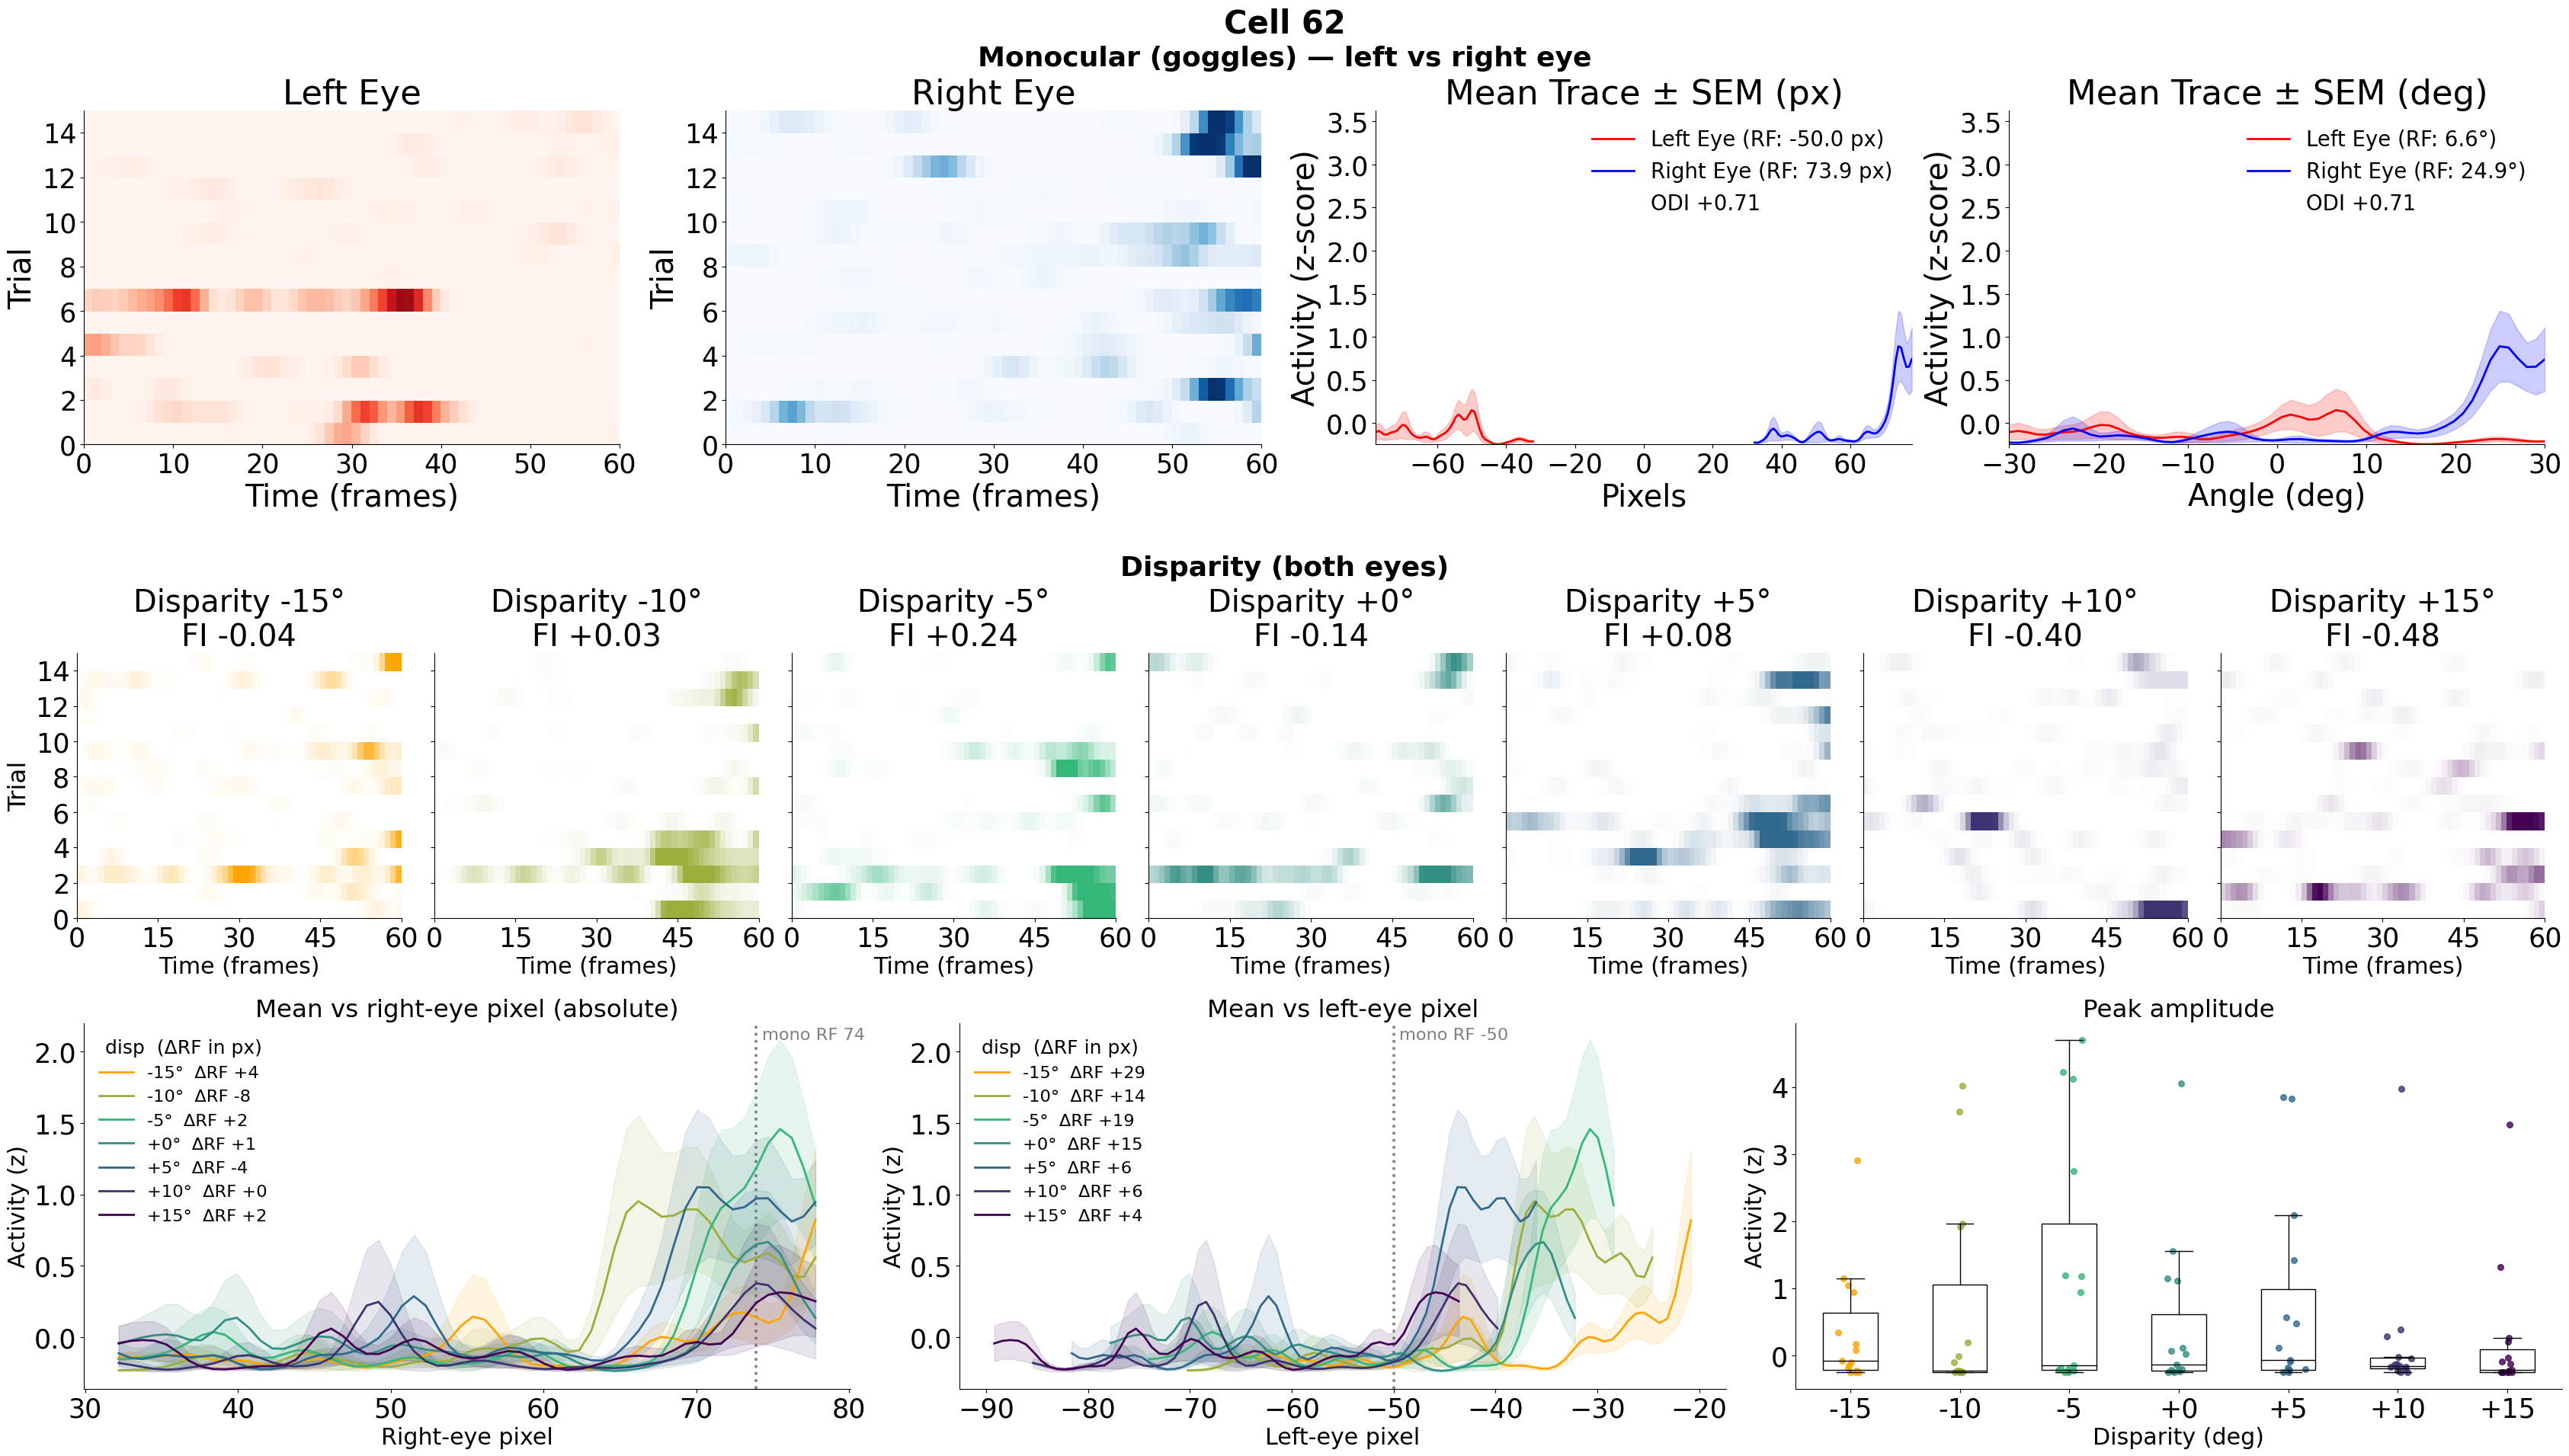

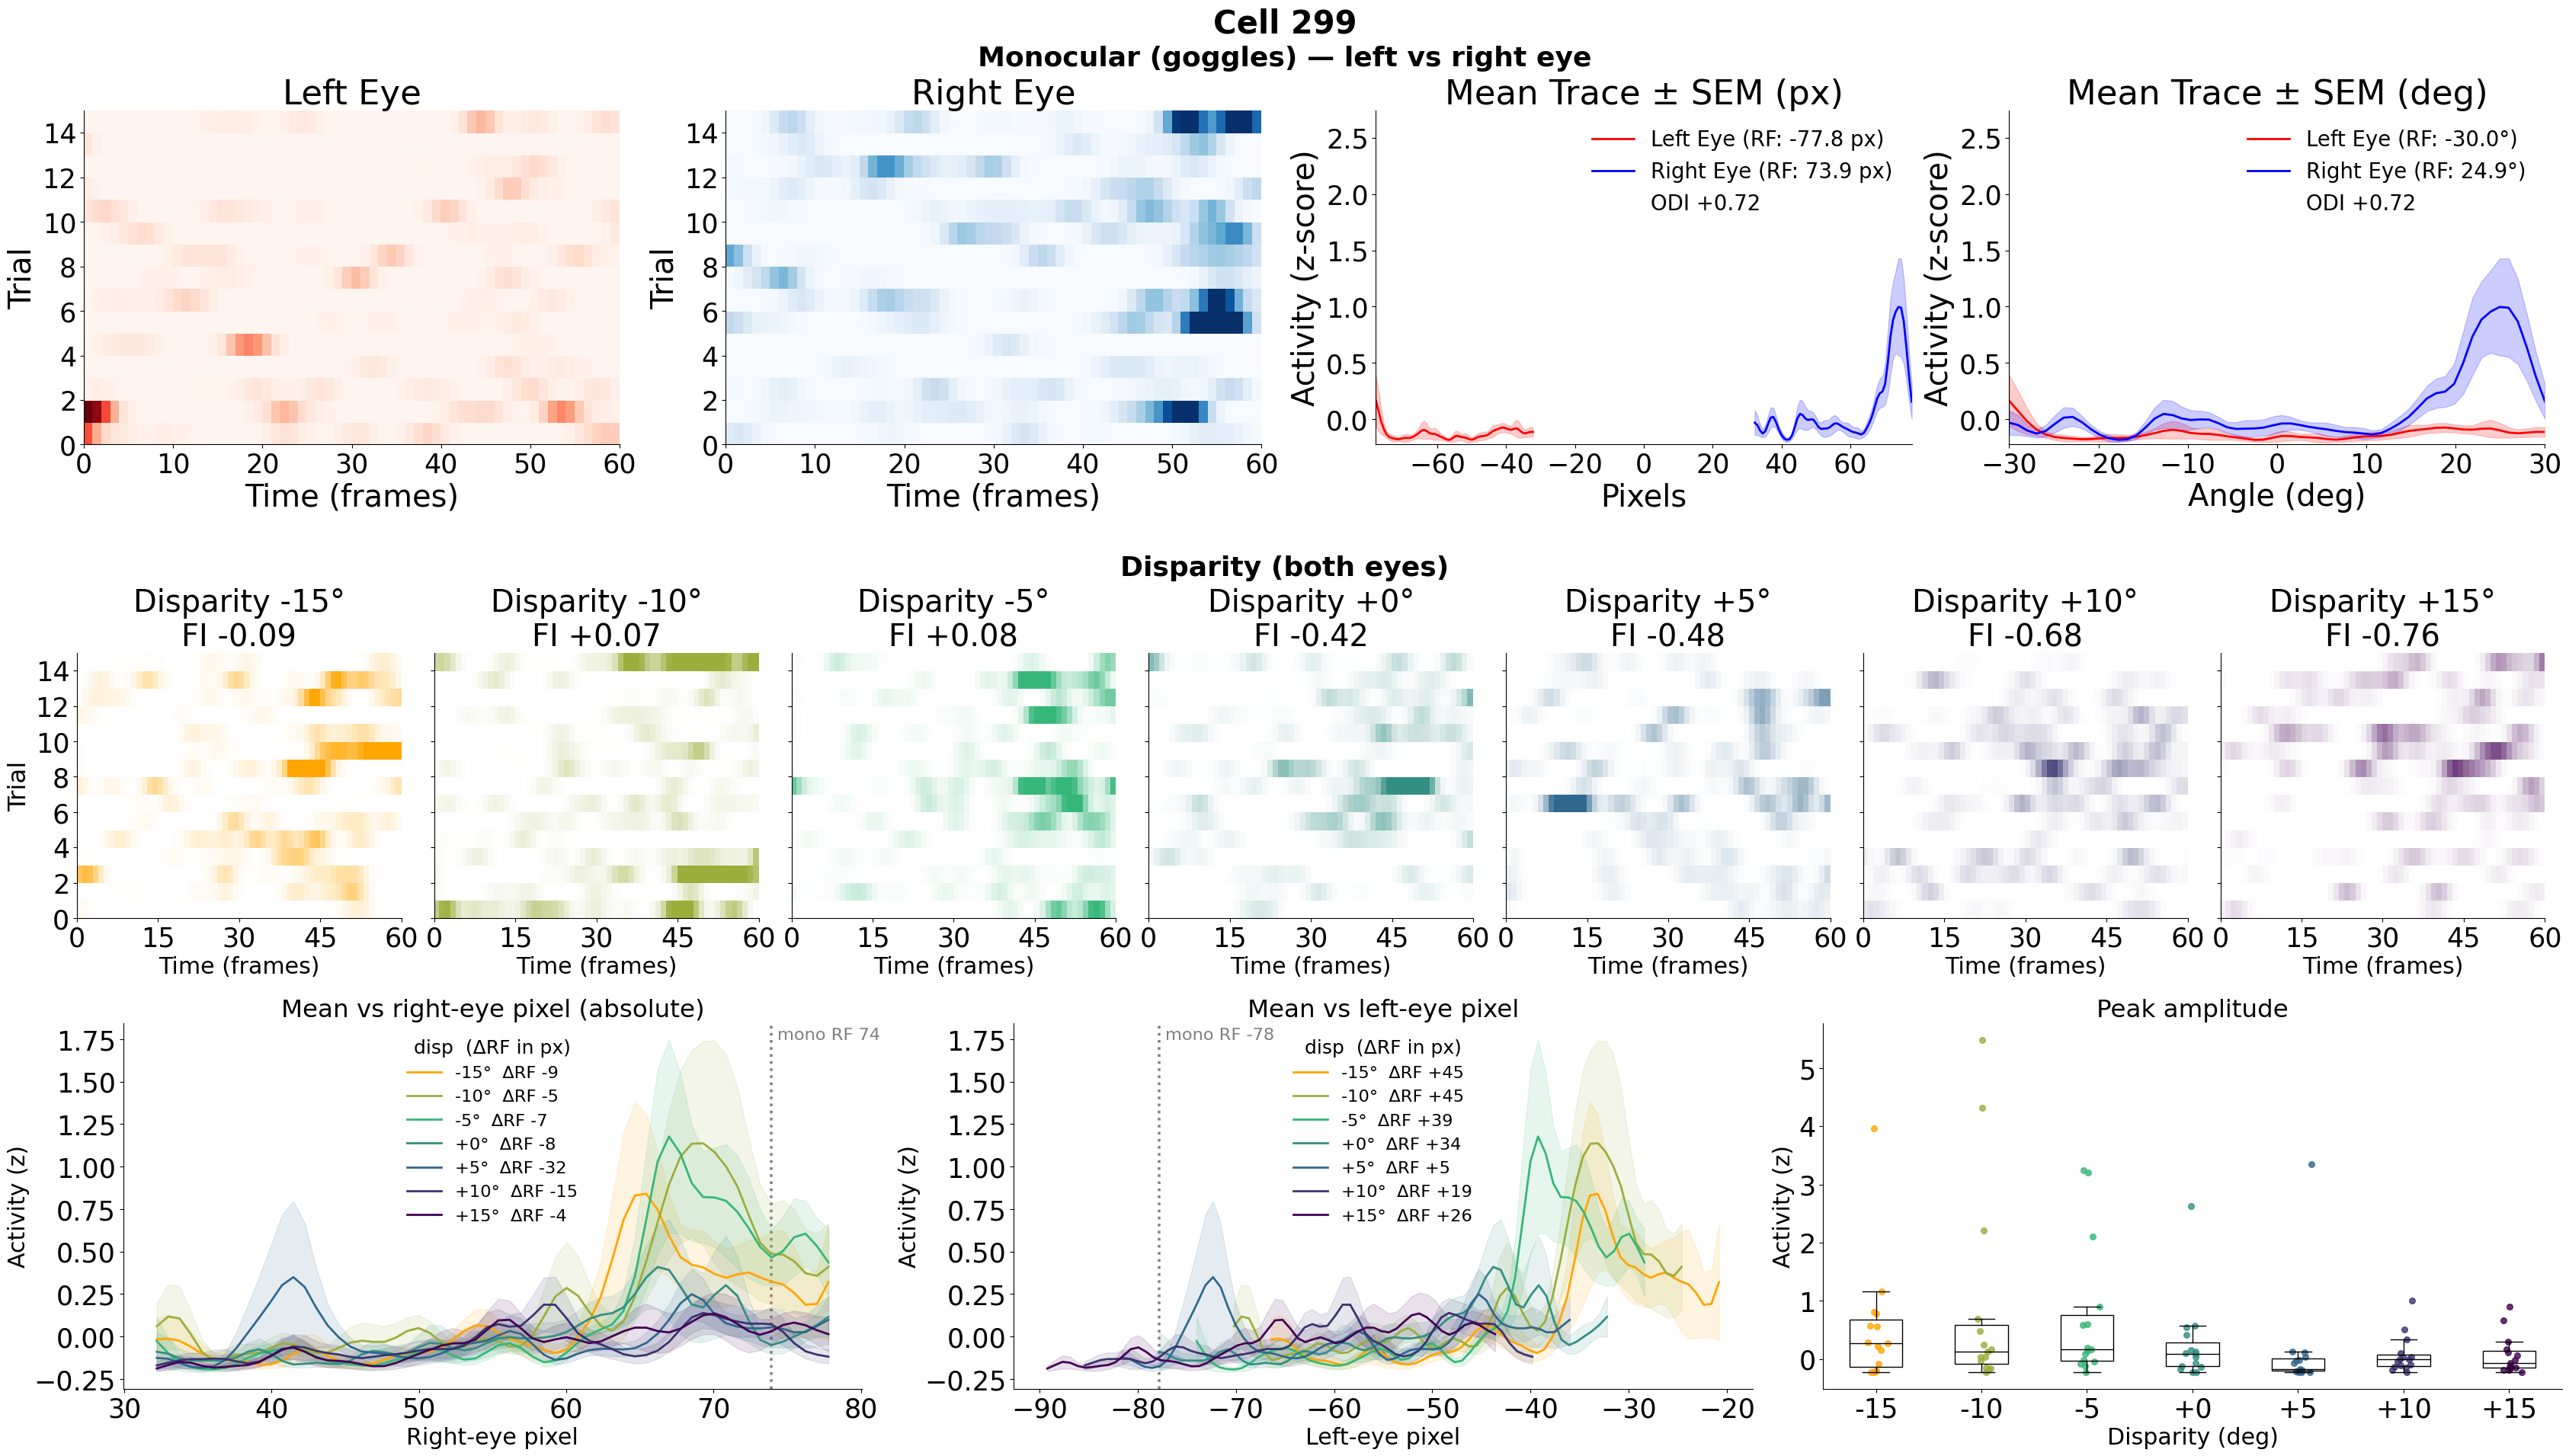

In [6]:
for cell in both:
    fig = viz.make_combined_plot(int(cell), units='px')
    plt.show()
    plt.show()

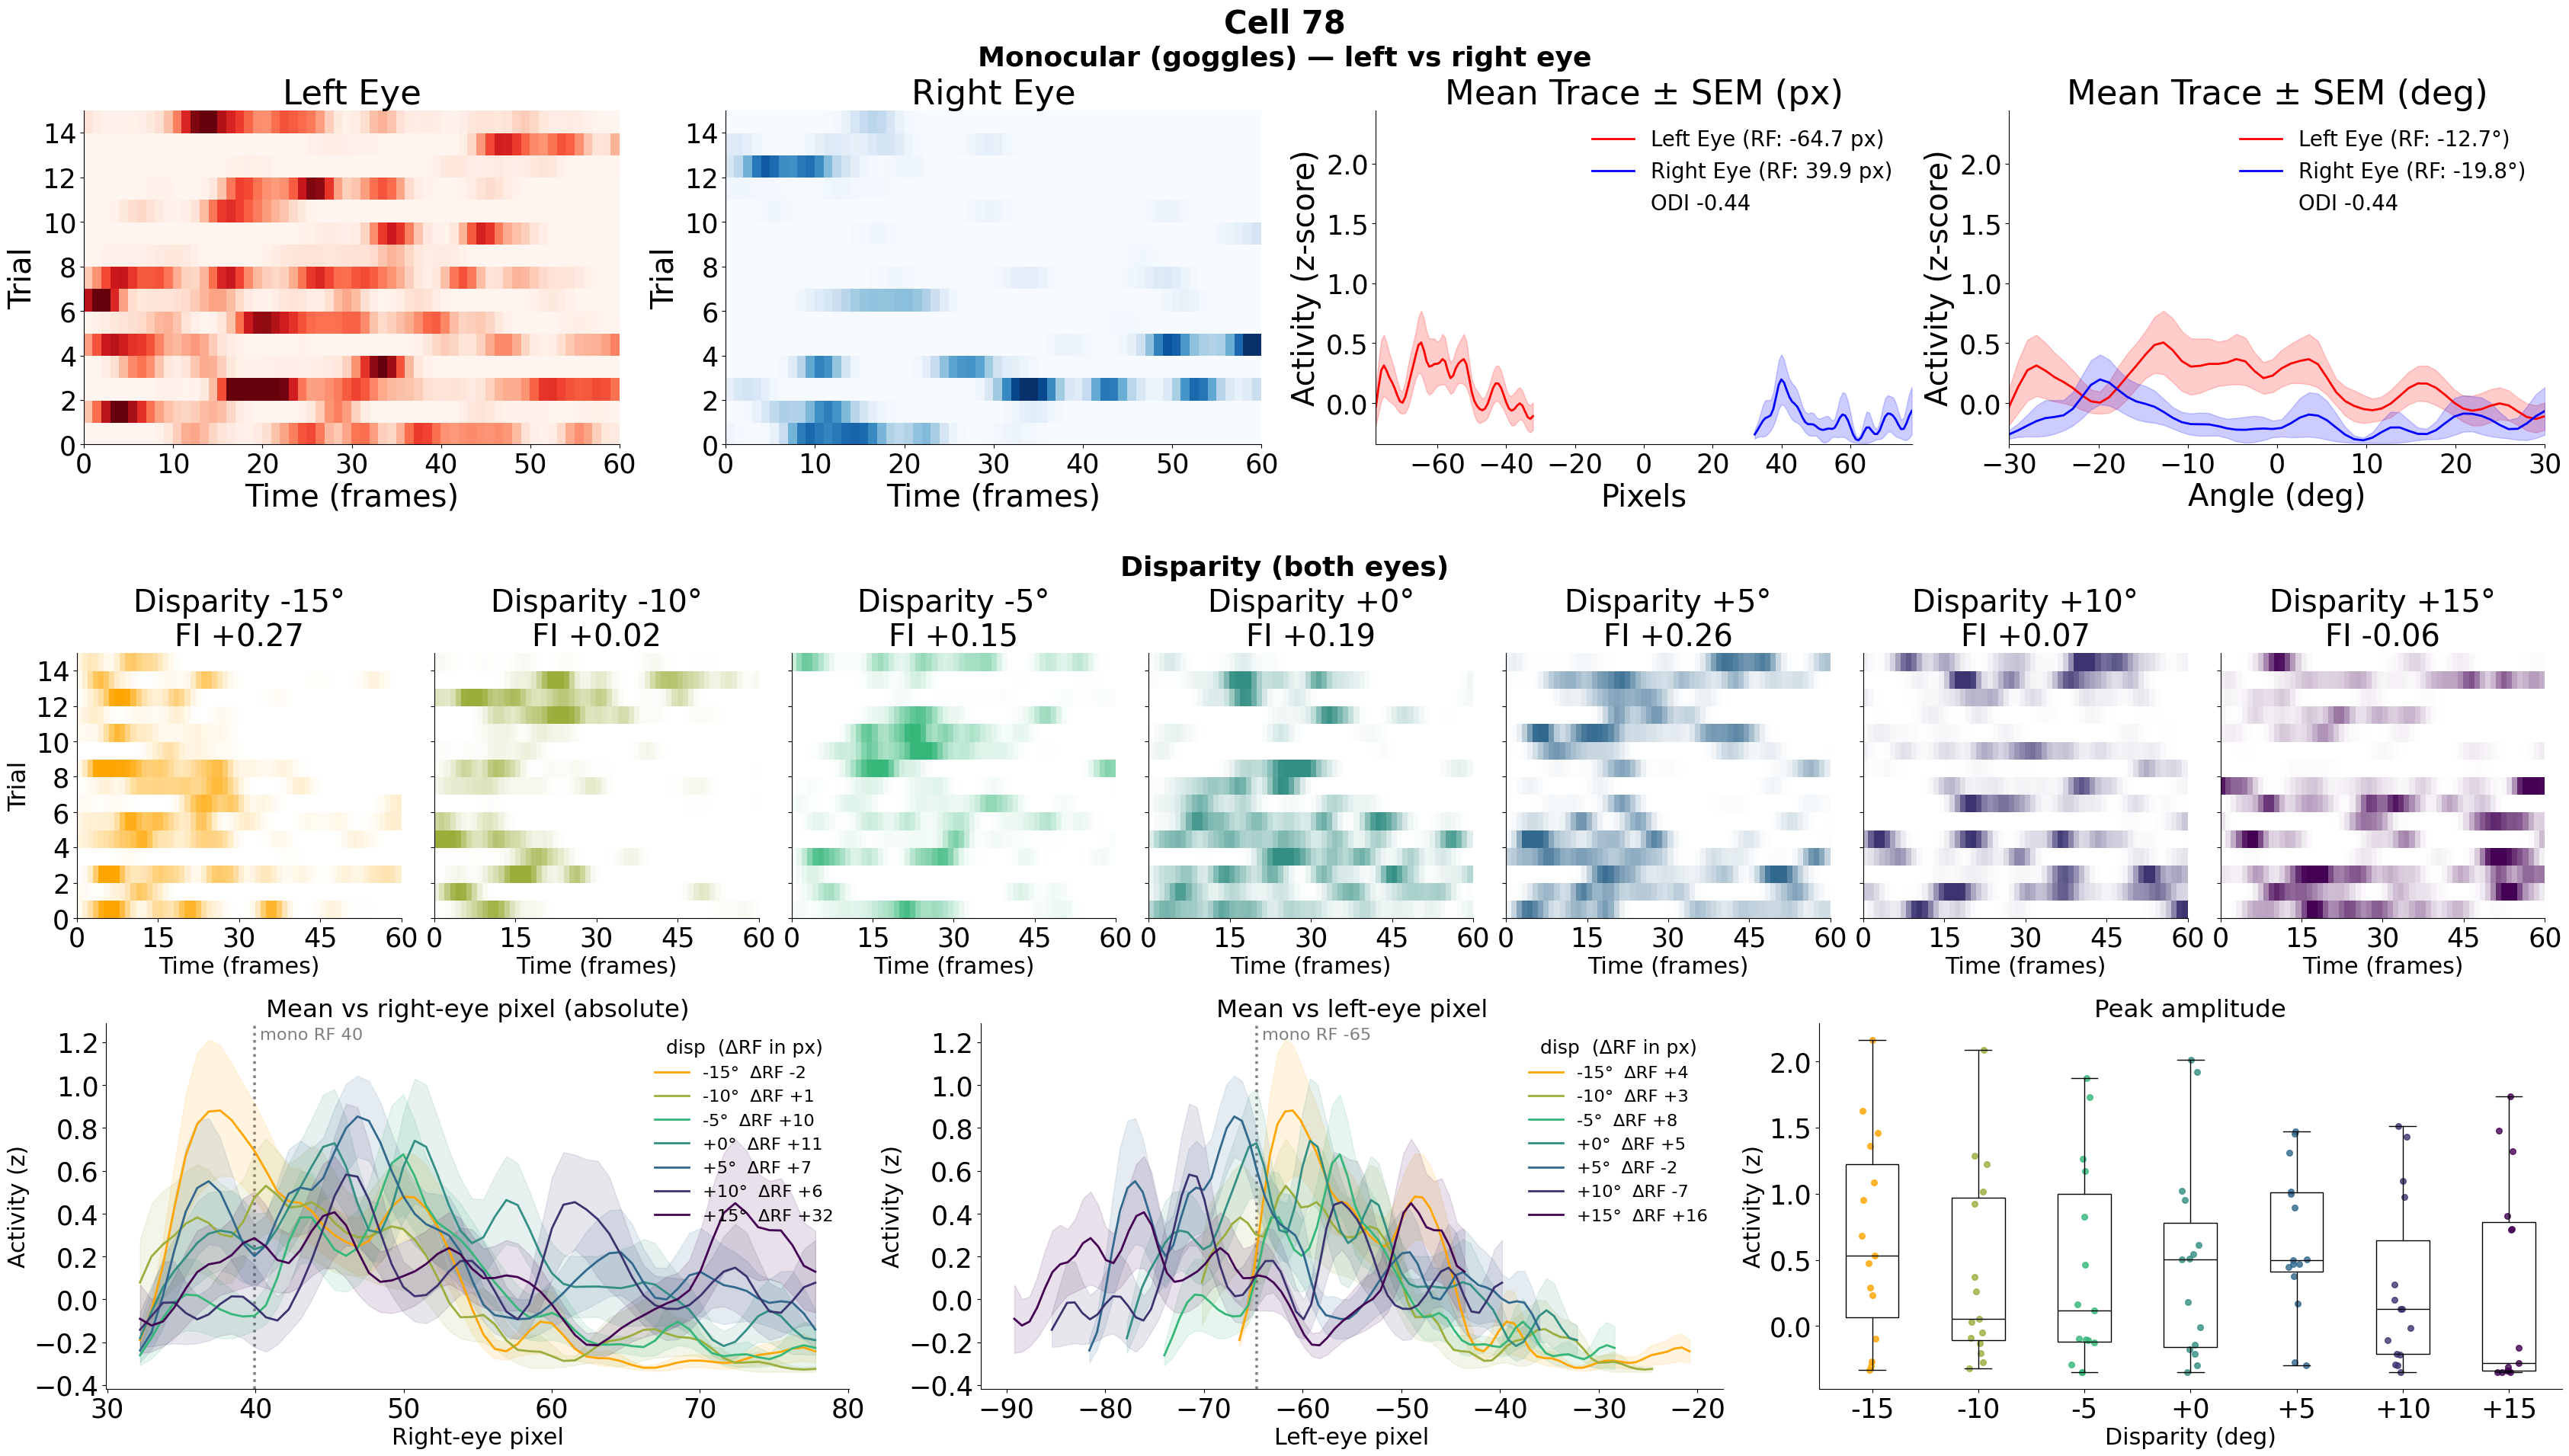

In [15]:
fig = viz.make_combined_plot(int(78), units='px')
plt.show()

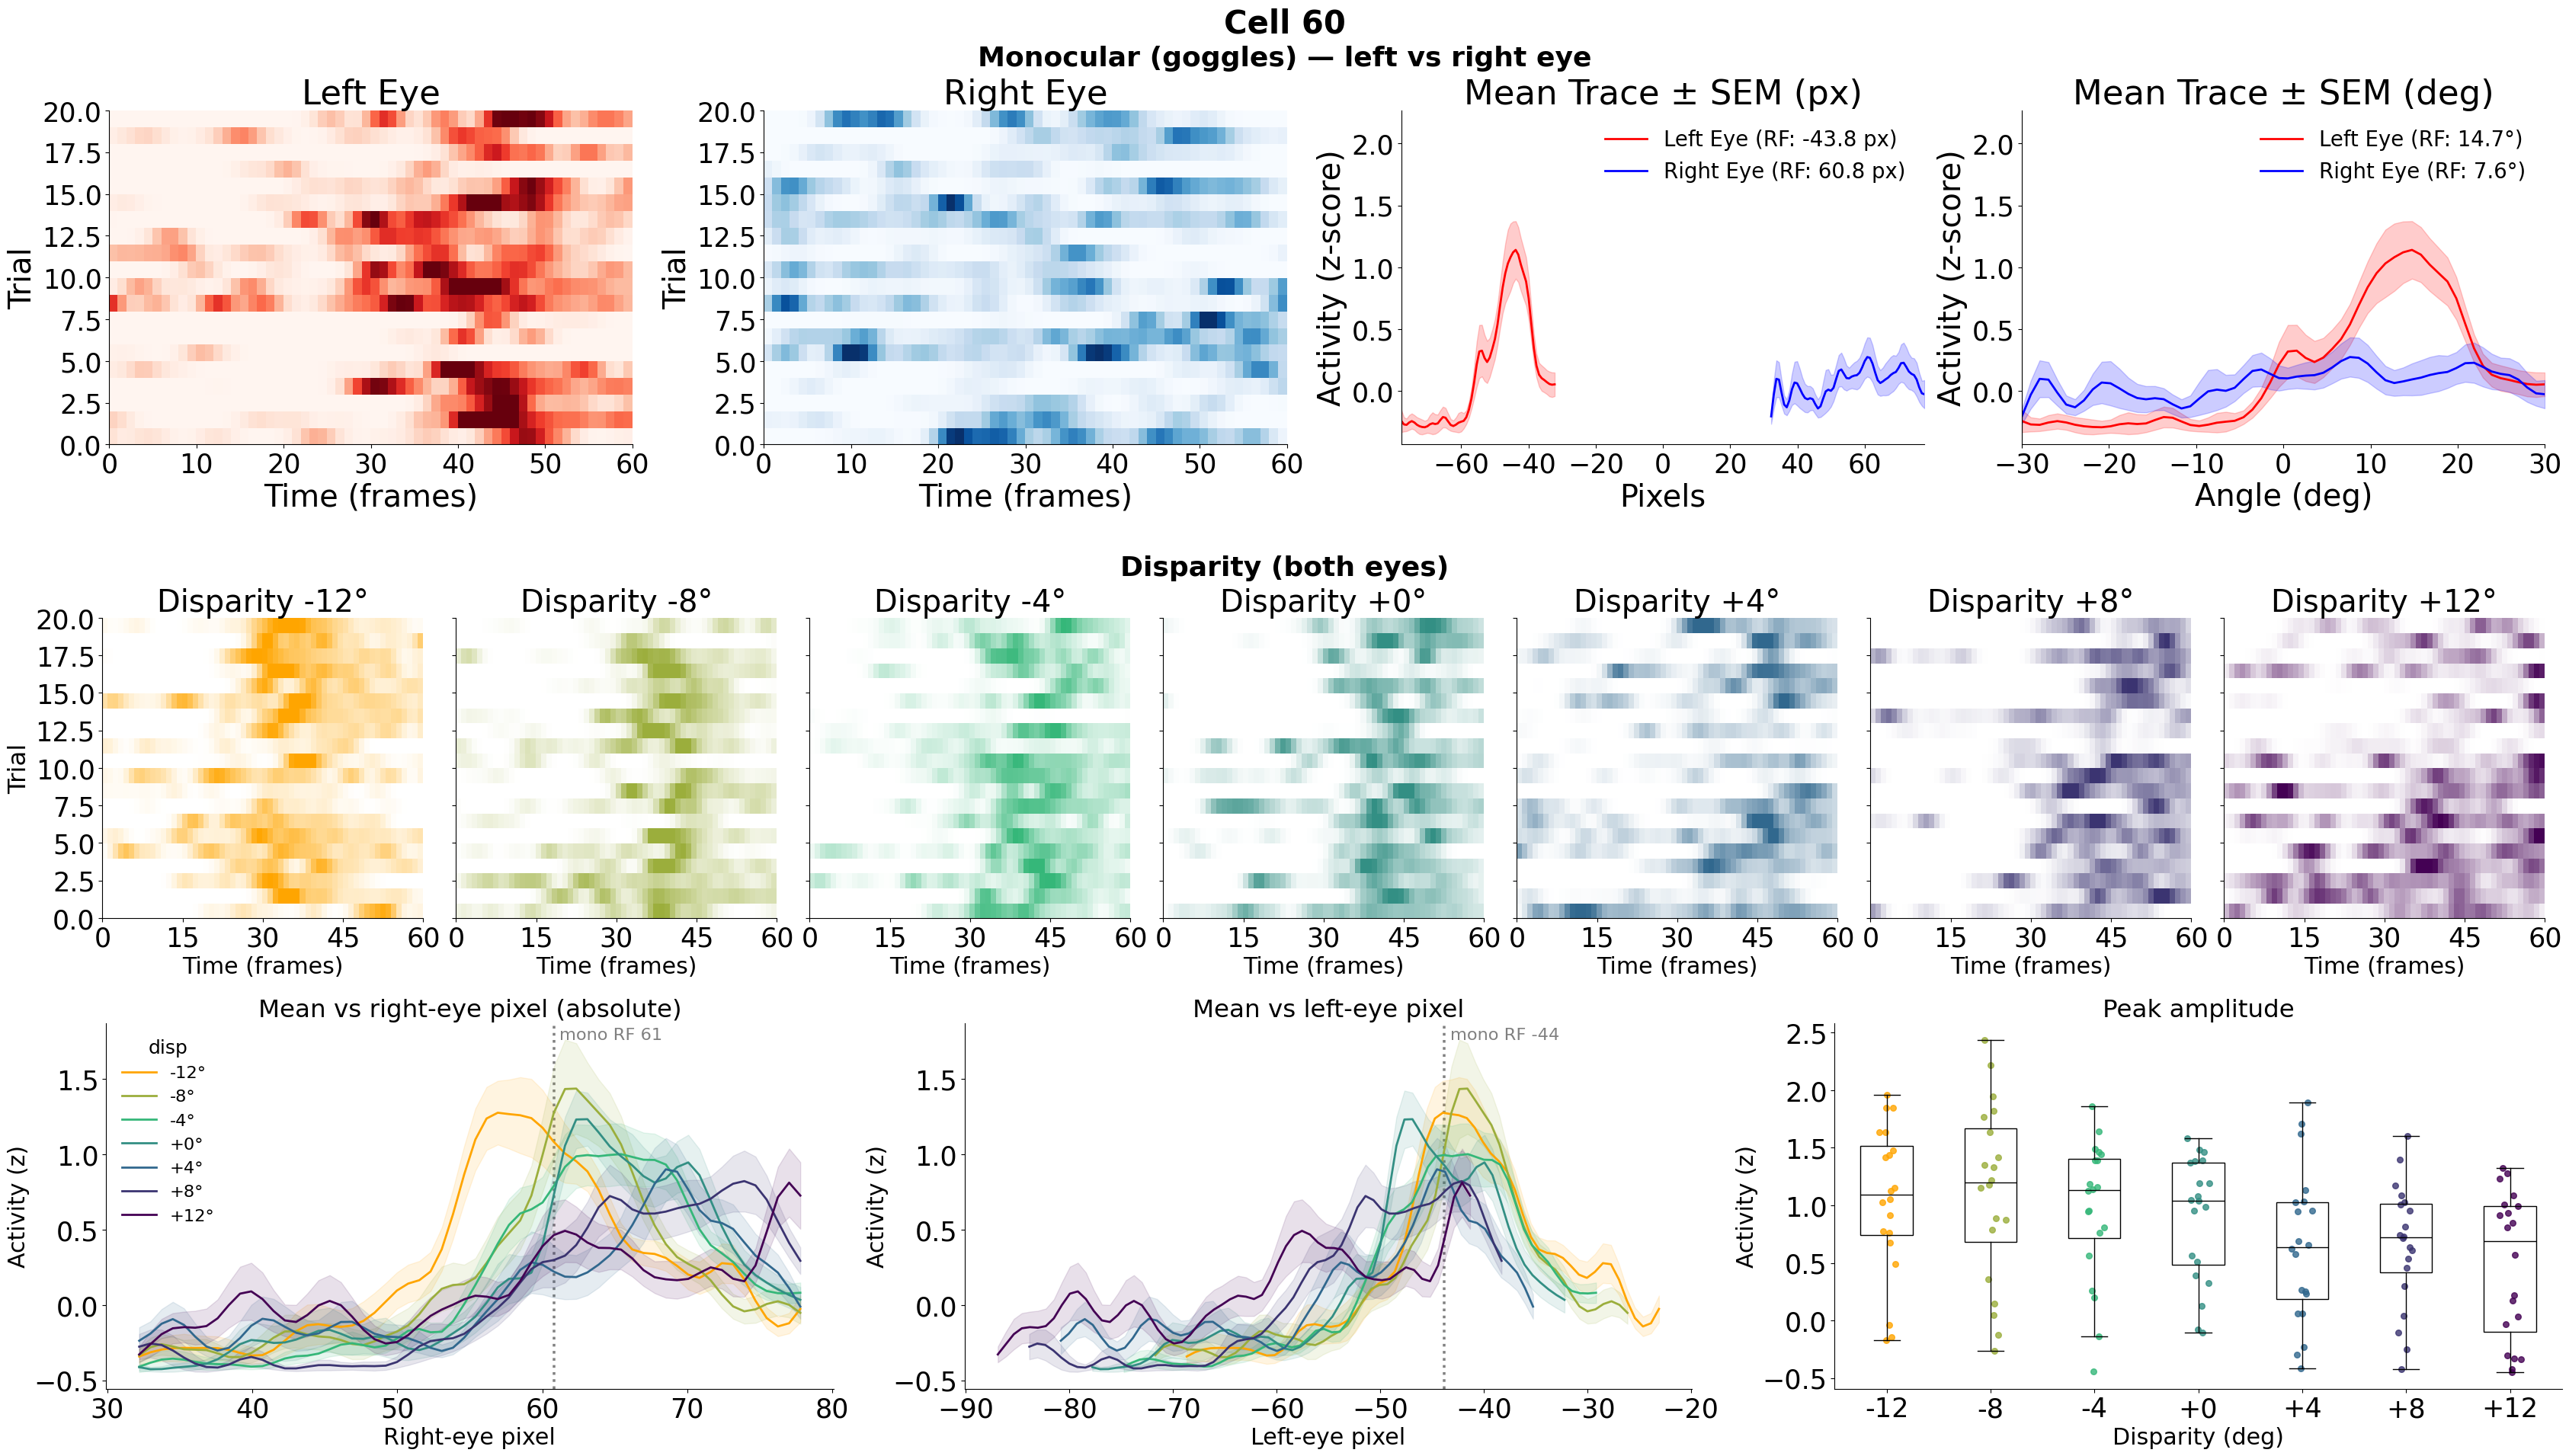

In [45]:
fig = viz.make_combined_plot(int(60), units='px')

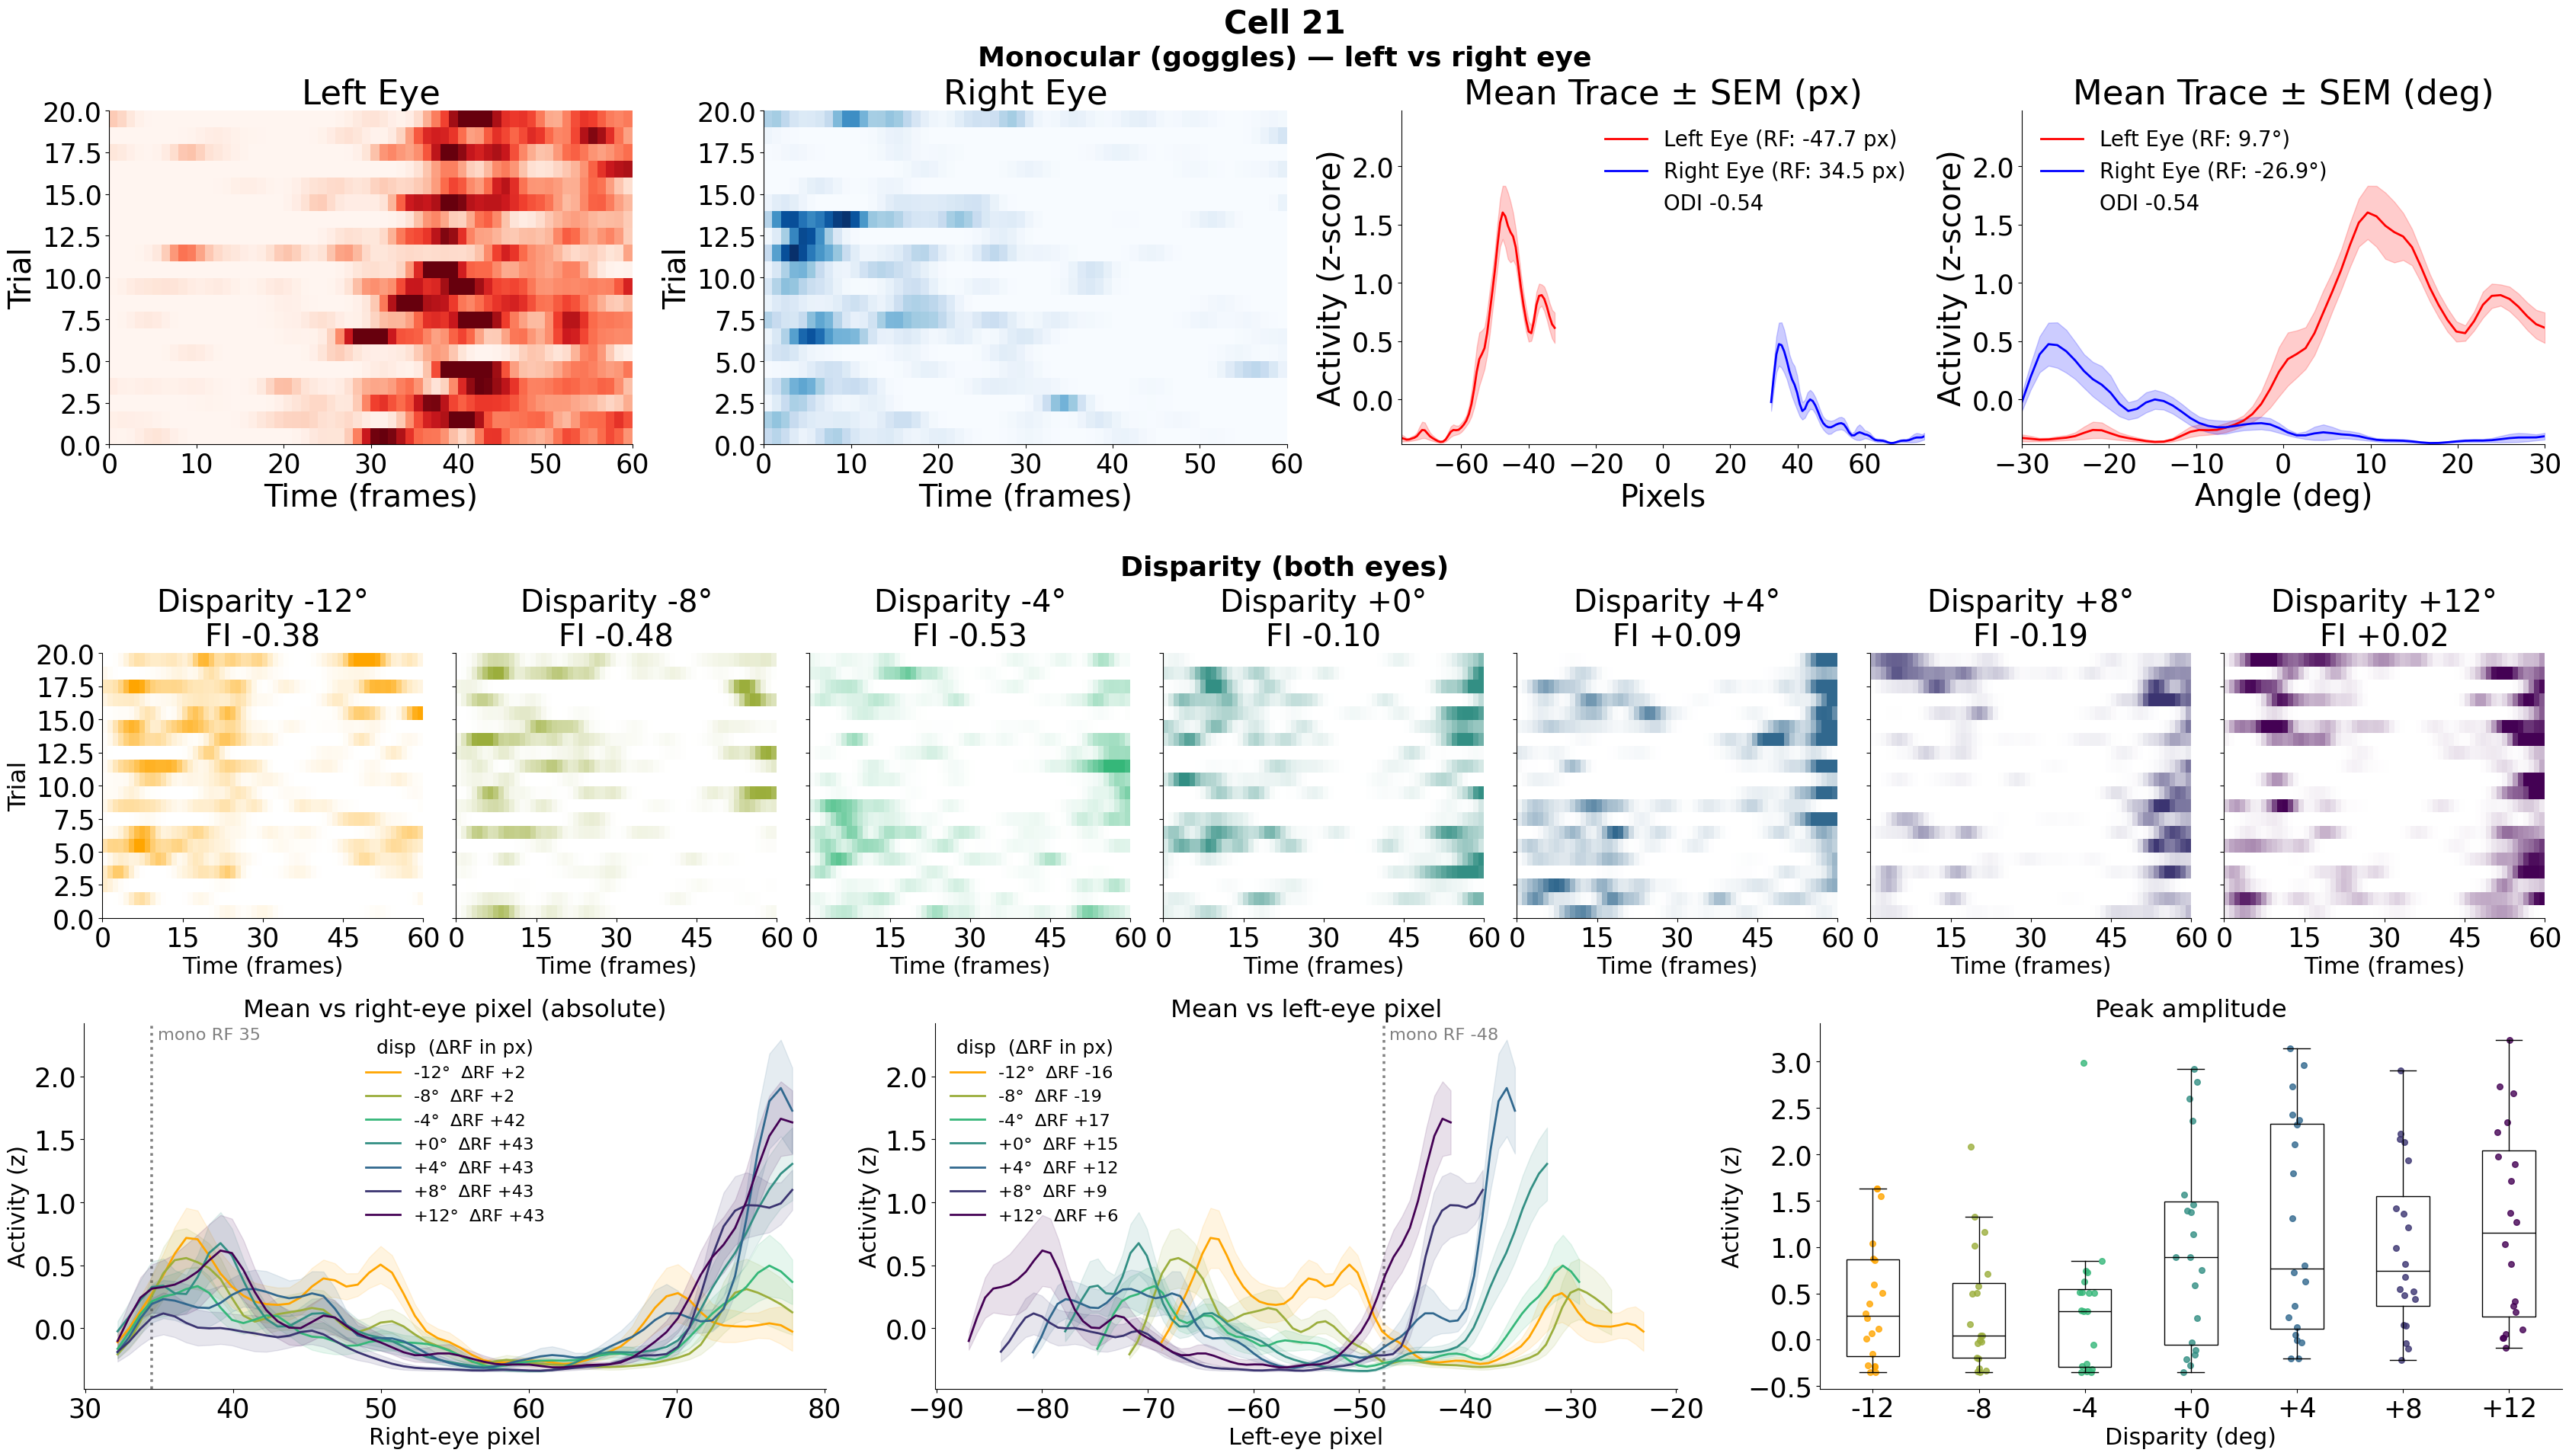

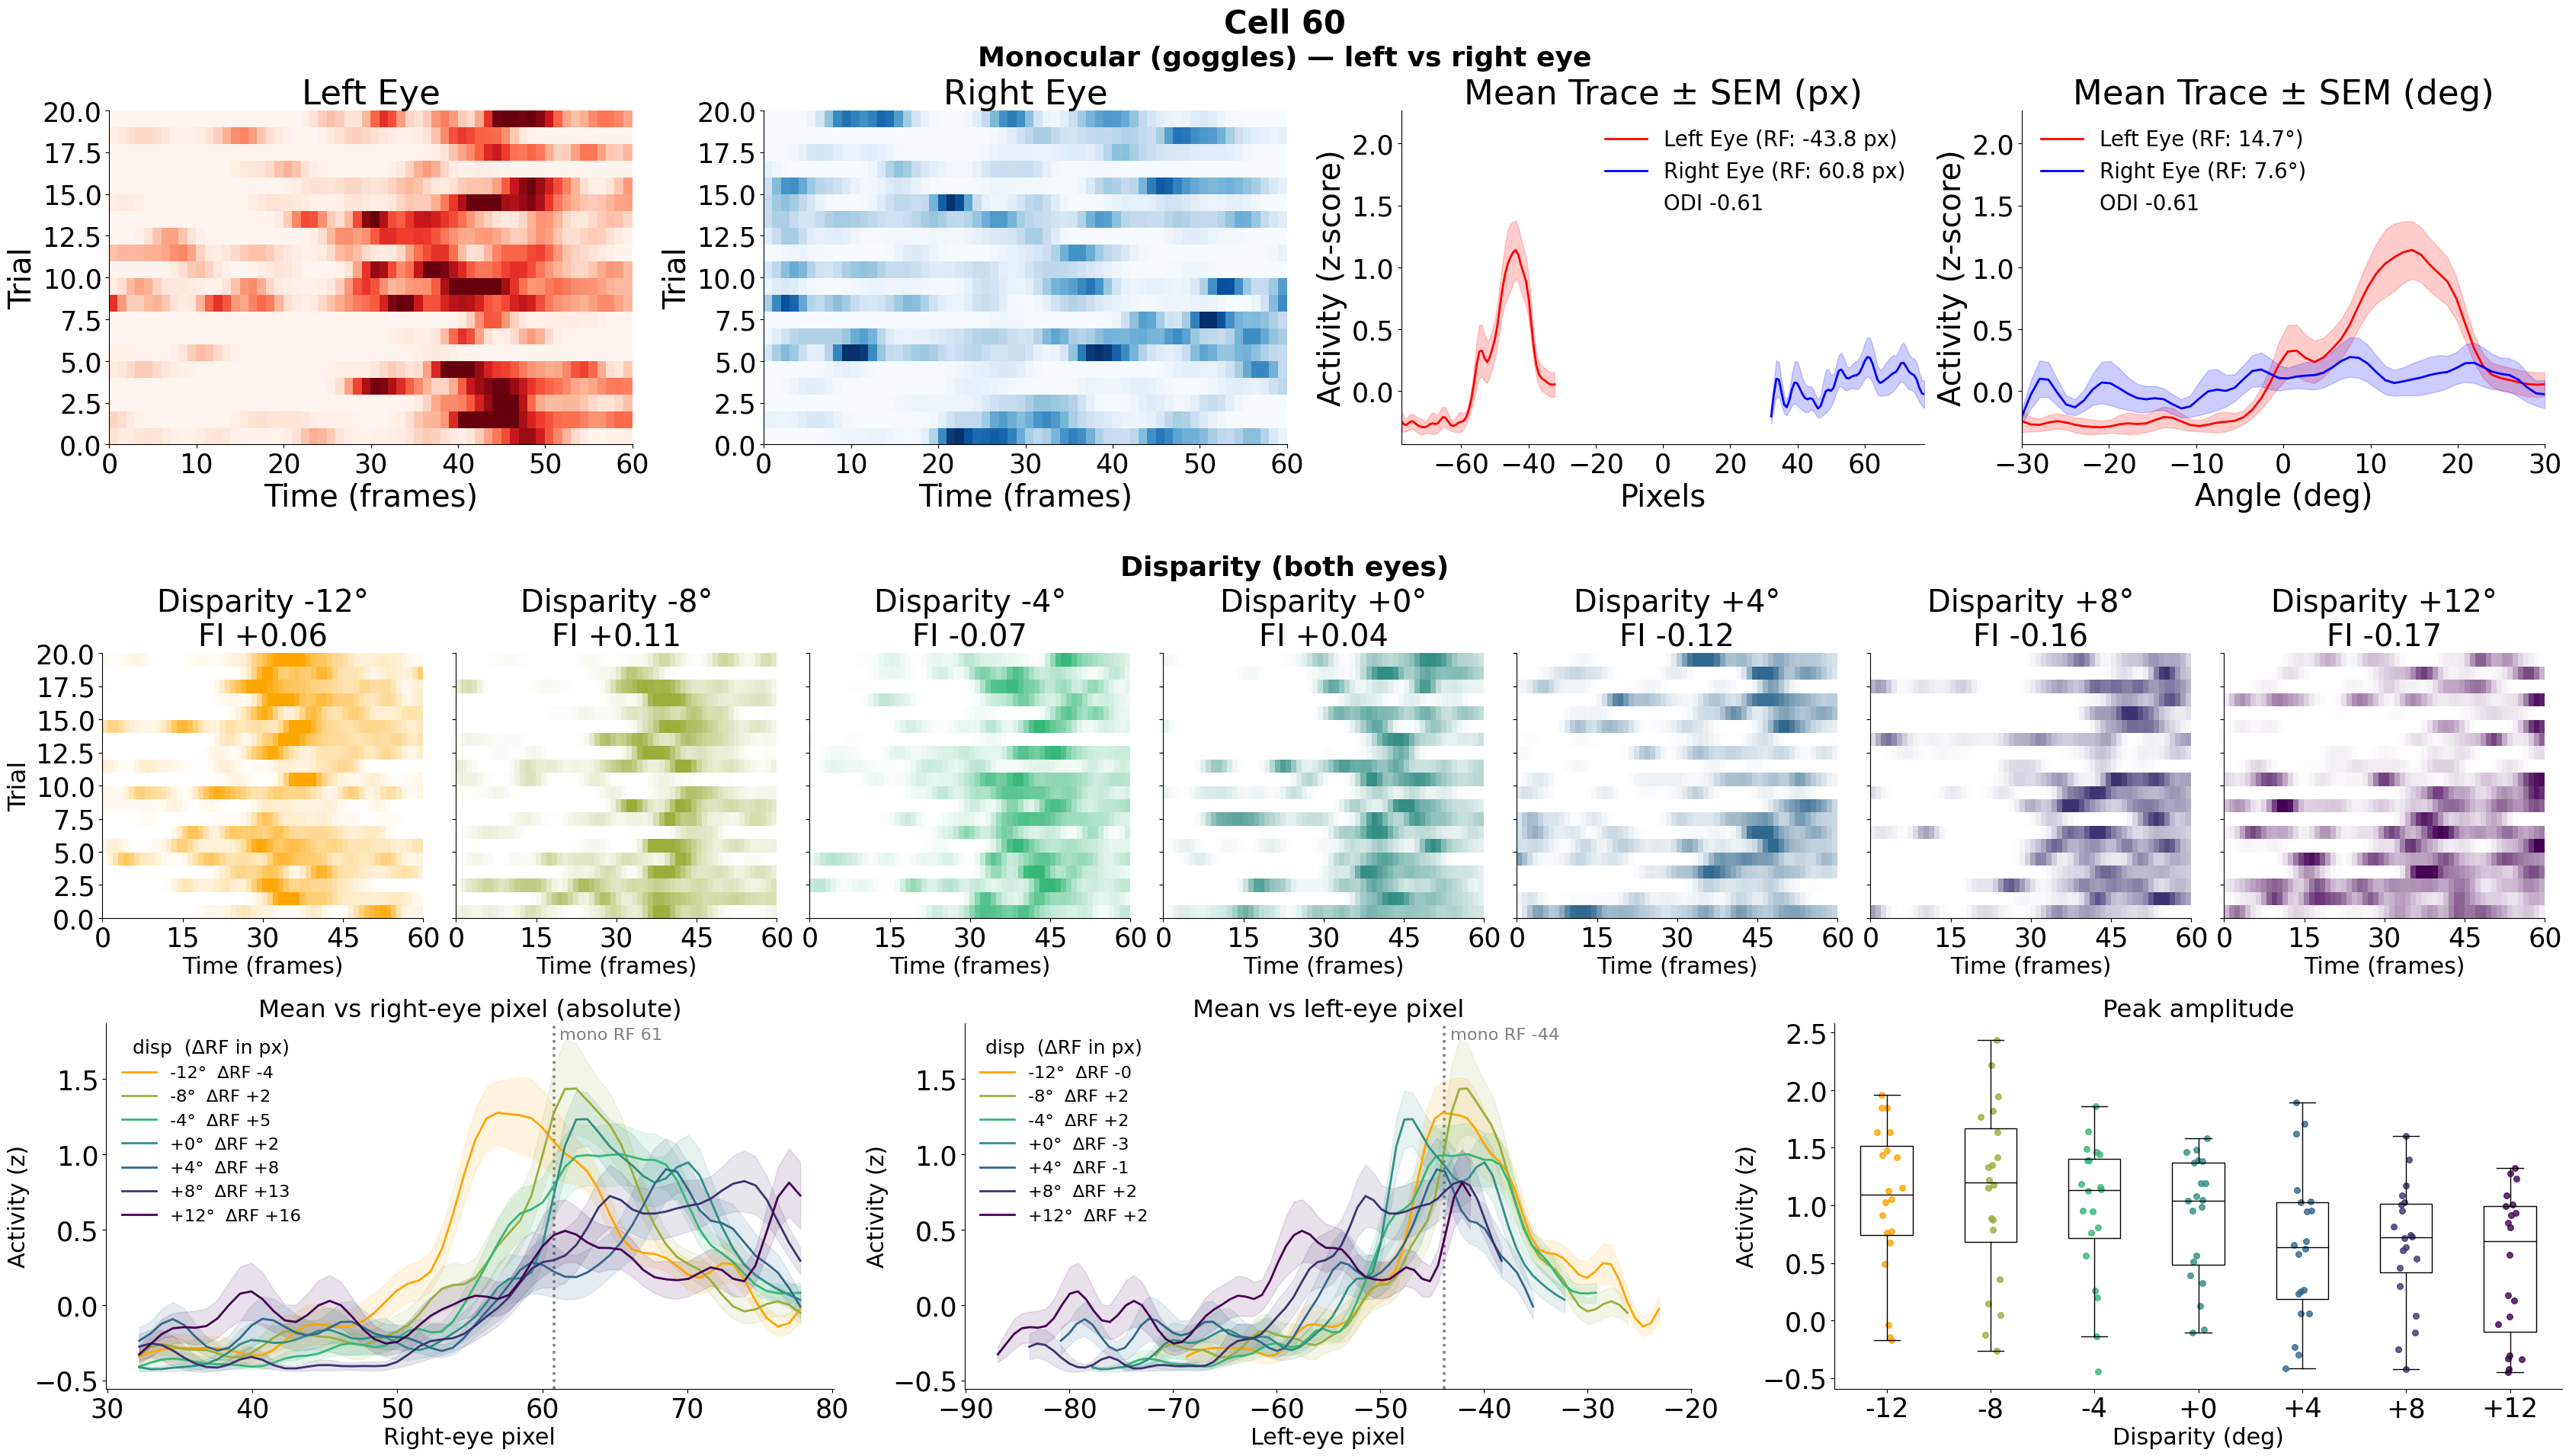

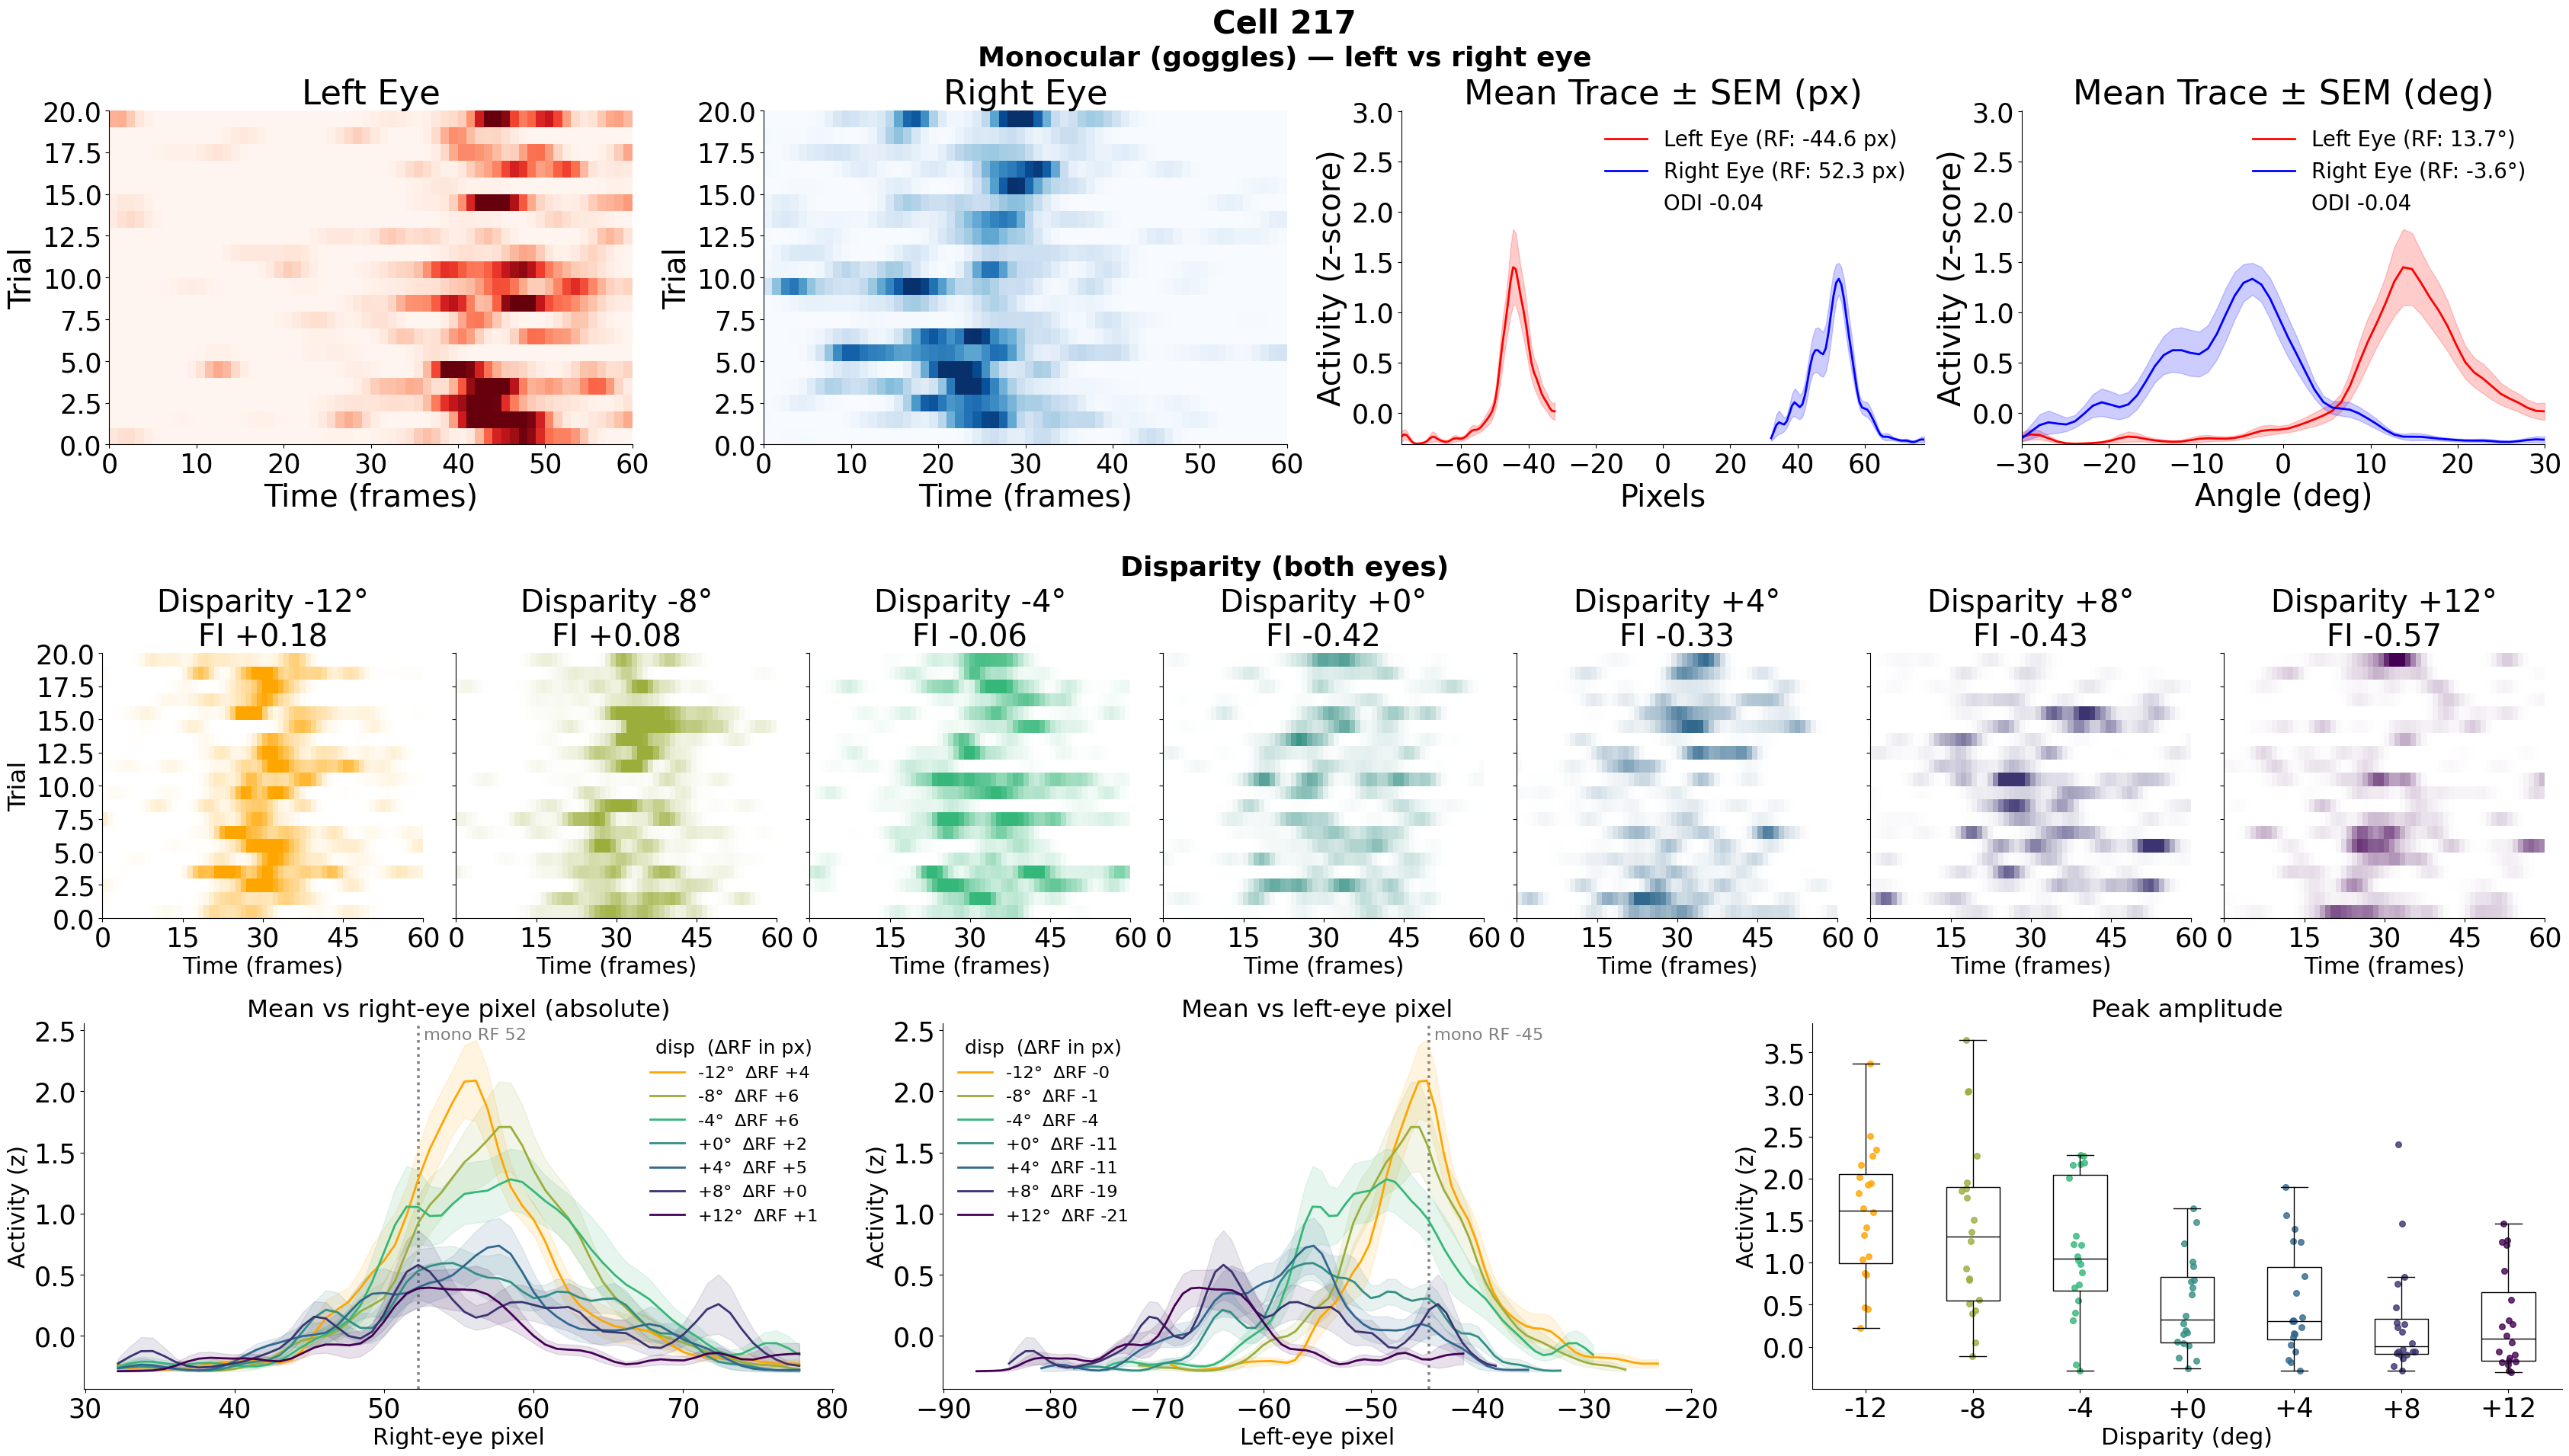

In [69]:
# per-cell response plots, stacked: monocular (left eye) | disparity
viz = CrossExperimentVisualization(None, M, D)
for cell in both:
    viz.make_combined_plot(int(cell), units='px')
    plt.show()

median 96.6 px | range 44.7 .. 144.4


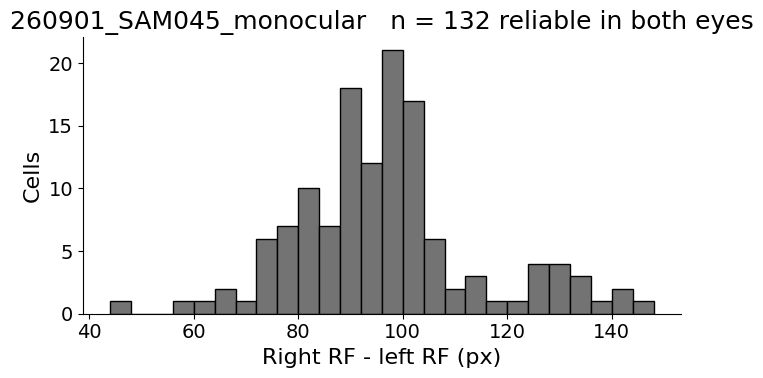

In [92]:
# --- difference between the two eyes' RF positions, reliable cells ---
import numpy as np, matplotlib.pyplot as plt

RHO = 0.7
df = cea.monocular_df
sel = (df['right_reliable'] & df['left_reliable']
       & (df['right_mean_corr'] >= RHO) & (df['left_mean_corr'] >= RHO))

# Rebuild each pixel from the stored RF *index*, not from the left_px column: on an
# angle-calibrated session that column comes out positive, because the range it was
# taken from is already signed and analyze_cell_stats negates it a second time.
# get_signed_screen_range is the accessor that gets this right in either format.
lpx = M.get_signed_screen_range('left')[df.loc[sel, 'left_rf'].to_numpy()]
rpx = M.get_signed_screen_range('right')[df.loc[sel, 'right_rf'].to_numpy()]

diff = rpx - lpx          # signed axis: left panel negative, right positive

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(diff, bins=np.arange(np.floor(diff.min()), np.ceil(diff.max()) + 4, 4),
        color='0.45', edgecolor='black')
ax.set_xlabel('Right RF - left RF (px)')
ax.set_ylabel('Cells')
ax.set_title(f'{M.session_name}   n = {int(sel.sum())} reliable in both eyes')
plt.tight_layout()

print(f"median {np.median(diff):.1f} px | range {diff.min():.1f} .. {diff.max():.1f}")

In [11]:
from scipy.stats import linregress
import numpy as np, matplotlib.pyplot as plt

RHO = 0.7
df = cea.monocular_df
sel = (df['right_reliable'] & df['left_reliable']
       & (df['right_mean_corr'] >= RHO) & (df['left_mean_corr'] >= RHO))
lpx = M.get_signed_screen_range('left')[df.loc[sel, 'left_rf'].to_numpy()]
rpx = M.get_signed_screen_range('right')[df.loc[sel, 'right_rf'].to_numpy()]
diff = rpx - lpx
xs = np.linspace(rpx.min(), rpx.max(), 50)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

f1 = linregress(rpx, diff)
ax1.scatter(rpx, diff, s=26, color='0.35', alpha=0.75, edgecolor='none')
ax1.plot(xs, f1.intercept + f1.slope * xs, color='crimson', lw=2)
ax1.axhline(np.median(diff), color='steelblue', ls='--', lw=1.5, label='median diff')
ax1.set_xlabel('Right RF (px)'); ax1.set_ylabel('Right RF - left RF (px)')
ax1.set_title(f'slope {f1.slope:+.2f} px/px   r {f1.rvalue:+.2f}   p {f1.pvalue:.1e}', fontsize=11)
ax1.legend(frameon=False, fontsize=9)

# the control: diff contains rpx, so it tracks rpx by construction UNLESS the left
# RF moves too. Slope ~1 here means the eyes agree and panel 1 is real; slope ~0
# means the left RF is fixed and panel 1 is just rpx re-plotted.
f2 = linregress(rpx, lpx)
ax2.scatter(rpx, lpx, s=26, color='0.35', alpha=0.75, edgecolor='none')
ax2.plot(xs, f2.intercept + f2.slope * xs, color='crimson', lw=2, label='fit')
ax2.plot(xs, xs - np.median(diff), color='seagreen', ls='--', lw=2, label='slope 1 (eyes agree)')
ax2.set_xlabel('Right RF (px)'); ax2.set_ylabel('Left RF (px)')
ax2.set_title(f'slope {f2.slope:+.2f} px/px   r {f2.rvalue:+.2f}   p {f2.pvalue:.1e}', fontsize=11)
ax2.legend(frameon=False, fontsize=9)

fig.suptitle(f'{M.session_name}   n = {int(sel.sum())} reliable in both eyes')
plt.tight_layout()

ValueError: zero-size array to reduction operation minimum which has no identity

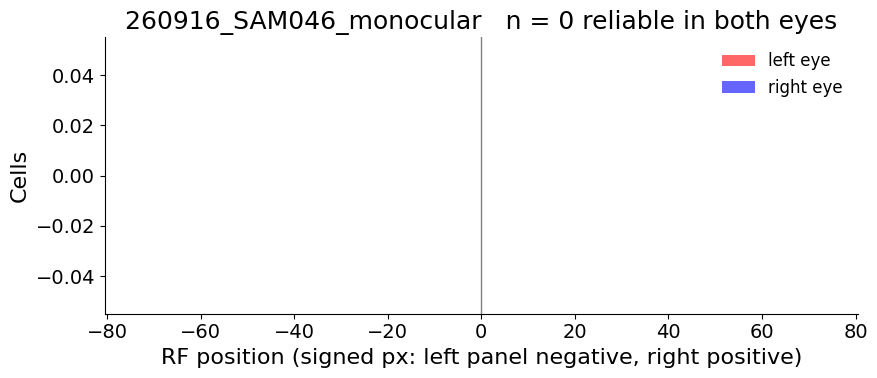

In [12]:
import numpy as np, matplotlib.pyplot as plt

RHO = 0.7
df = cea.monocular_df
sel = (df['right_reliable'] & df['left_reliable']
       & (df['right_mean_corr'] >= RHO) & (df['left_mean_corr'] >= RHO))

fig, ax = plt.subplots(figsize=(9, 4))
for eye, color in (('left', 'red'), ('right', 'blue')):
    # Count on the stored RF *index* and place each bar at its own stimulus position:
    # one bar per frame the stimulus actually visited. (Binning the left_px column
    # instead would also put the left eye on the wrong side of zero, since that
    # column is sign-flipped on an angle-calibrated session.)
    rng = M.get_signed_screen_range(eye)
    counts = np.bincount(df.loc[sel, f'{eye}_rf'].to_numpy(), minlength=len(rng))
    ax.bar(rng, counts[:len(rng)], width=abs(np.diff(rng).mean()), color=color,
           alpha=0.6, edgecolor='none', label=f'{eye} eye')

ax.axvline(0, color='0.5', lw=1)          # nasal edge, where the panels meet
ax.set_xlabel('RF position (signed px: left panel negative, right positive)')
ax.set_ylabel('Cells')
ax.set_title(f'{M.session_name}   n = {int(sel.sum())} reliable in both eyes')
ax.legend(frameon=False)
plt.tight_layout()

In [13]:
fig = viz.make_combined_plot(int(575), units='px')

NameError: name 'viz' is not defined